# **Retail Sales and Customer Analysis Using Python**

### **1. Import Libraries and Load Dataset**

**Purpose:** Load the retail dataset into Python.

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Online Retail.xlsx")
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### **2. Data Exploration**
*   **Purpose**: Understand the dataset's size, columns and missing values.
*   **Key finding**: The original dataset contains 541,909 rows and 8 columns, with missing customer IDs and product descriptions.




In [2]:

print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (541909, 8)

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


### **3. Data Cleaning and Revenue Calculation**
*  **Purpose:** Identify valid sales, cancelled invoices and records requiring investigation.
*  **Business purpose:** Prevent cancelled or invalid transactions from inflating sales revenue.




In [4]:

df["Transaction_Status"] = "Investigate"

cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
valid = ~cancelled & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)

df.loc[cancelled, "Transaction_Status"] = "Cancelled"
df.loc[valid, "Transaction_Status"] = "Normal Sale"

df["Sales_Revenue"] = 0.0
df.loc[valid, "Sales_Revenue"] = (
    df.loc[valid, "Quantity"] * df.loc[valid, "UnitPrice"]
)

normal_sales = df[valid].copy()


### **4. Sales Performance KPIs**
* **Purpose:** Calculate the business's most important sales metrics.



In [5]:

total_revenue = normal_sales["Sales_Revenue"].sum()
total_orders = normal_sales["InvoiceNo"].nunique()
units_sold = normal_sales["Quantity"].sum()
average_order_value = total_revenue / total_orders

print(f"Revenue: £{total_revenue:,.2f}")
print(f"Orders: {total_orders:,}")
print(f"Units Sold: {units_sold:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")


Revenue: £10,666,684.54
Orders: 19,960
Units Sold: 5,588,376
Average Order Value: £534.40


### **5. Monthly Sales Trend Analysis**
* **Purpose:** Identify high-performing months and sales patterns.
* **Key finding:** November 2011 generated approximately £1.51 million, the highest monthly revenue.




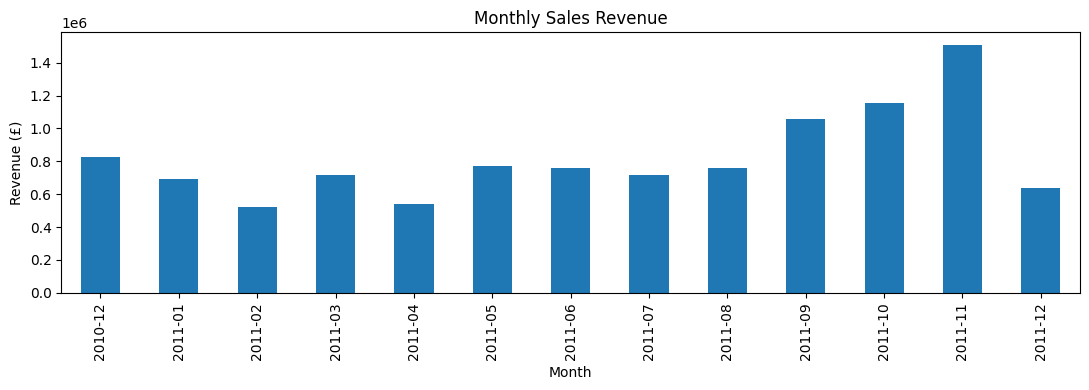

In [6]:

normal_sales["Month"] = (
    pd.to_datetime(normal_sales["InvoiceDate"])
    .dt.to_period("M")
)

monthly_sales = normal_sales.groupby("Month")["Sales_Revenue"].sum()

monthly_sales.plot(kind="bar", figsize=(11, 4))
plt.title("Monthly Sales Revenue")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()


### **6. Sales Performance by Country**
* **Purpose:** Identify the markets contributing the most revenue.
* **Key finding:** The United Kingdom generated approximately £9.03 million, or 84.6% of total sales revenue.



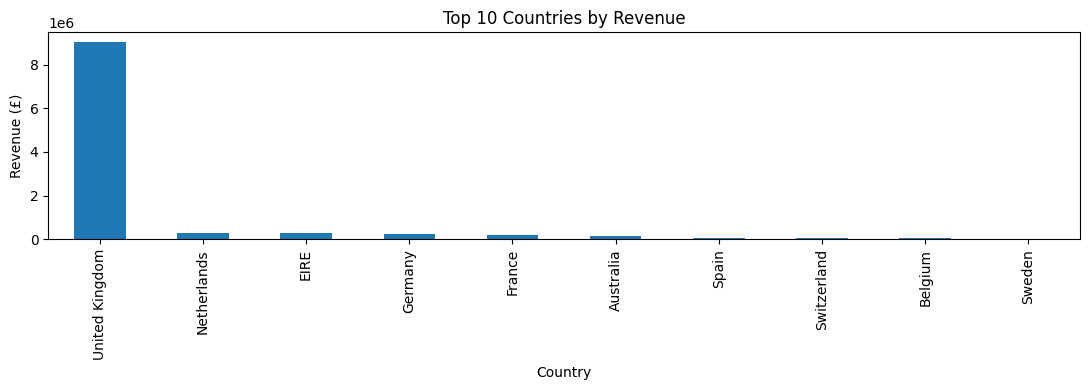

In [7]:

country_sales = (
    normal_sales.groupby("Country")["Sales_Revenue"]
    .sum().nlargest(10)
)

country_sales.plot(kind="bar", figsize=(11, 4))
plt.title("Top 10 Countries by Revenue")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()


### **7. Top 10 Products by Revenue**
* **Purpose:** Identify the merchandise generating the highest revenue.





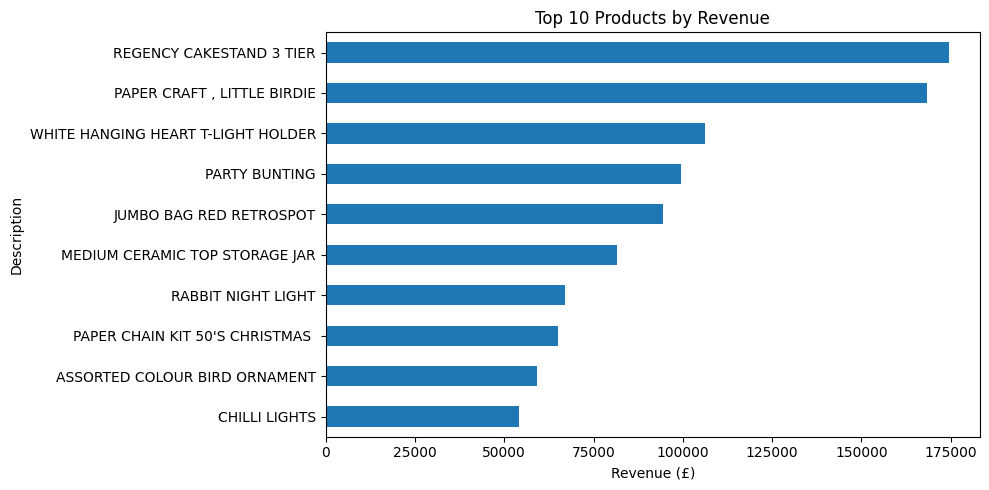

In [8]:

exclude_codes = ["DOT", "POST", "M", "BANK CHARGES", "C2"]

products = normal_sales[
    ~normal_sales["StockCode"].astype(str).str.upper().isin(exclude_codes)
]

top_products = (
    products.groupby("Description")["Sales_Revenue"]
    .sum().nlargest(10)
)

top_products.sort_values().plot(kind="barh", figsize=(10, 5))
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.tight_layout()
plt.show()


### **8. Customer Analysis**
* **Purpose:** Identify the customer base and highest-spending customers.
* **Key findings:** 4,338 identifiable customers. Customer 14646 generated £280,206.02 in revenue.




In [9]:

customers = normal_sales.dropna(subset=["CustomerID"])

total_customers = customers["CustomerID"].nunique()

top_customers = (
    customers.groupby("CustomerID")["Sales_Revenue"]
    .sum().nlargest(10)
)

print("Unique Customers:", total_customers)
print(top_customers)


Unique Customers: 4338
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Sales_Revenue, dtype: float64


### **9. Repeat Customer Analysis**
* **Purpose:** Measure repeat purchasing behaviour.
* **Key finding:** 2,845 customers purchased more than once, giving a repeat customer rate of 65.58%



In [10]:

customer_orders = customers.groupby("CustomerID")["InvoiceNo"].nunique()

repeat_customers = (customer_orders > 1).sum()
repeat_rate = repeat_customers / len(customer_orders) * 100

print(f"Repeat Customers: {repeat_customers:,}")
print(f"Repeat Customer Rate: {repeat_rate:.2f}%")


Repeat Customers: 2,845
Repeat Customer Rate: 65.58%


### **10. Average Customer Spending**
* **Purpose:** Measure average revenue per identifiable customer across the dataset period.
* **Key finding:** Average spending per identifiable customer was £2,054.27




In [11]:

customer_spending = customers.groupby("CustomerID")["Sales_Revenue"].sum()

average_spending = customer_spending.mean()

print(f"Average Customer Spending: £{average_spending:,.2f}")


Average Customer Spending: £2,054.27
